<a href="https://colab.research.google.com/github/datnguyen76/thuchanhtrituenhantao/blob/main/Tuan_5.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Bài tập thực hành AI - Tuần 5

Notebook này được xây dựng theo cấu trúc tương tự các tuần trước (Markdown giải thích từng bước $\rightarrow$ Code thực thi & trực quan hóa $\rightarrow$ Bảng tổng hợp & nhận xét kết quả), sẵn sàng chạy trực tiếp trên Google Colab hoặc Jupyter Notebook.

---

## 0. Thiết lập môi trường & Nạp thư viện
Chạy ô code bên dưới để khởi tạo môi trường tính toán và nạp các thư viện cần thiết (`numpy`, `pandas`, `matplotlib`, `seaborn`, `scikit-learn`).

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

from sklearn.datasets import make_blobs, load_iris
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import (
    silhouette_score, davies_bouldin_score, adjusted_rand_score,
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, ConfusionMatrixDisplay, classification_report
)
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline

plt.rcParams["figure.figsize"] = (10, 5)
sns.set_style("whitegrid")
print("Đã nạp thư viện thành công!")

Đã nạp thư viện thành công!


---
## 1. Khám phá dữ liệu (EDA) & Tiền xử lý
Trong phần này, ta thực hiện kiểm tra chất lượng dữ liệu, thống kê mô tả, trực quan hóa phân bố và chuẩn hóa đặc trưng trước khi áp dụng thuật toán.

In [2]:
iris = load_iris(as_frame=True)
df = iris.frame.copy()

print("Kích thước dữ liệu:", df.shape)
print("Số lượng giá trị thiếu:", df.isnull().sum().sum())
print("Số dòng trùng lặp:", df.duplicated().sum())
print("Phân bố nhãn (target):")
print(df["target"].value_counts().sort_index())
display(df.head())

# Thống kê mô tả các cột đặc trưng
display(df.drop(columns=["target"]).describe().T[["count", "mean", "std", "min", "50%", "max"]])

Kích thước dữ liệu: (150, 5)
Số lượng giá trị thiếu: 0
Số dòng trùng lặp: 1
Phân bố nhãn (target):
target
0    50
1    50
2    50
Name: count, dtype: int64


,sepal length (cm),sepal width (cm),petal length (cm),petal width (cm),target
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0


,count,mean,std,min,50%,max
sepal length (cm),150.0,5.843333,0.828066,4.3,5.80,7.9
sepal width (cm),150.0,3.057333,0.435866,2.0,3.00,4.4
petal length (cm),150.0,3.758000,1.765298,1.0,4.35,6.9
petal width (cm),150.0,1.199333,0.762238,0.1,1.30,2.5


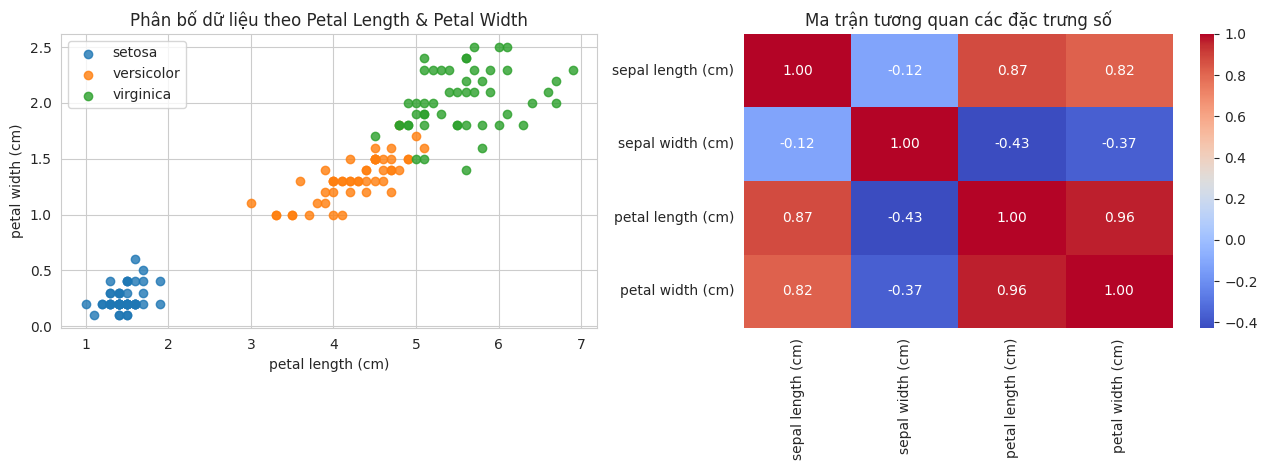

In [3]:
# Trực quan hóa pairwise / scatter & tương quan đặc trưng
fig, axes = plt.subplots(1, 2, figsize=(13, 4.8))

for target_val, label_name in enumerate(iris.target_names):
    sub = df[df["target"] == target_val]
    axes[0].scatter(sub["petal length (cm)"], sub["petal width (cm)"], label=label_name, alpha=0.8)

axes[0].set_title("Phân bố dữ liệu theo Petal Length & Petal Width")
axes[0].set_xlabel("petal length (cm)")
axes[0].set_ylabel("petal width (cm)")
axes[0].legend()

sns.heatmap(df.drop(columns=["target"]).corr(), annot=True, fmt=".2f", cmap="coolwarm", ax=axes[1])
axes[1].set_title("Ma trận tương quan các đặc trưng số")

plt.tight_layout()
plt.show()

### Nhận xét bước EDA:
* Bộ dữ liệu gồm 150 mẫu và 4 đặc trưng số, không có giá trị thiếu và phân bố đều giữa 3 nhóm.
* Các đặc trưng cánh hoa (`petal length`, `petal width`) có tương quan rất mạnh với nhau và tách biệt các nhóm rõ ràng hơn so với đặc trưng đài hoa (`sepal`).

---
## 2. Thực nghiệm phân cụm & Đánh giá chất lượng (Elbow, Silhouette, ARI)
Áp dụng chuẩn hóa dữ liệu (`StandardScaler`) và đánh giá số cụm tối ưu bằng phương pháp **Elbow** và **Silhouette Score**, đồng thời so sánh với nhãn thực tế qua **Adjusted Rand Index (ARI)**.

,k,Inertia (WCSS),Silhouette Score,ARI (vs target)
0,2,222.36,0.5818,0.5681
1,3,139.82,0.4599,0.6201
2,4,114.09,0.3869,0.4728
3,5,90.93,0.3459,0.4348
4,6,81.54,0.3171,0.4502
5,7,72.63,0.3202,0.4340


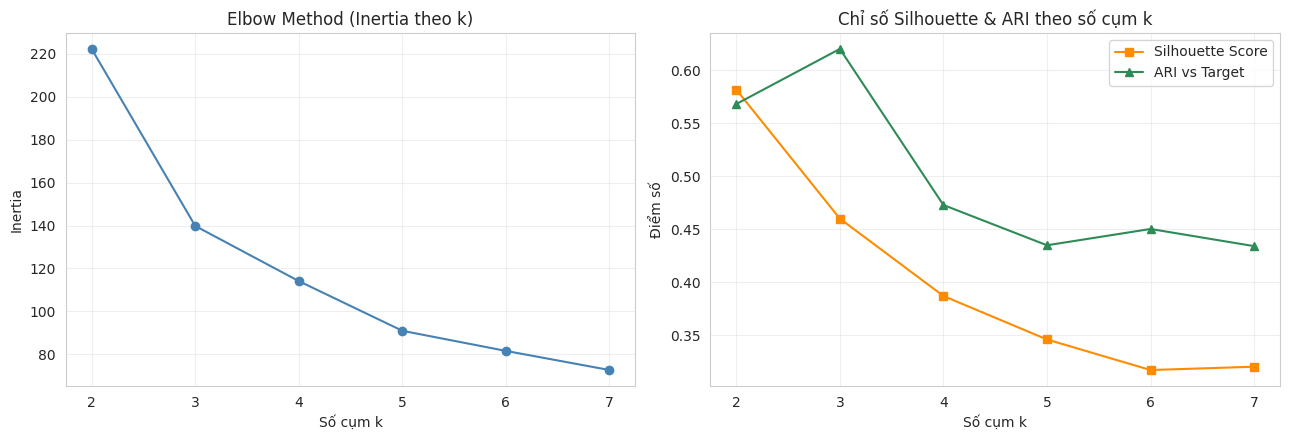

In [4]:
X = df.drop(columns=["target"])
y_true = df["target"]

scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

k_values = range(2, 8)
inertias = []
sil_scores = []
ari_scores = []

for k in k_values:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels_k = km.fit_predict(X_scaled)
    inertias.append(km.inertia_)
    sil_scores.append(silhouette_score(X_scaled, labels_k))
    ari_scores.append(adjusted_rand_score(y_true, labels_k))

df_k_eval = pd.DataFrame({
    "k": list(k_values),
    "Inertia (WCSS)": [round(v, 2) for v in inertias],
    "Silhouette Score": [round(v, 4) for v in sil_scores],
    "ARI (vs target)": [round(v, 4) for v in ari_scores]
})
display(df_k_eval)

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(list(k_values), inertias, marker="o", color="steelblue")
axes[0].set_title("Elbow Method (Inertia theo k)")
axes[0].set_xlabel("Số cụm k")
axes[0].set_ylabel("Inertia")
axes[0].grid(alpha=0.3)

axes[1].plot(list(k_values), sil_scores, marker="s", color="darkorange", label="Silhouette Score")
axes[1].plot(list(k_values), ari_scores, marker="^", color="seagreen", label="ARI vs Target")
axes[1].set_title("Chỉ số Silhouette & ARI theo số cụm k")
axes[1].set_xlabel("Số cụm k")
axes[1].set_ylabel("Điểm số")
axes[1].legend()
axes[1].grid(alpha=0.3)

plt.tight_layout()
plt.show()

---
## 3. So sánh các thuật toán & Trực quan hóa kết quả bằng PCA (2D)
So sánh kết quả phân nhóm/dự đoán giữa nhiều mô hình trên cùng không gian đặc trưng chuẩn hóa và chiếu 2 chiều bằng `PCA` để trực quan hóa.

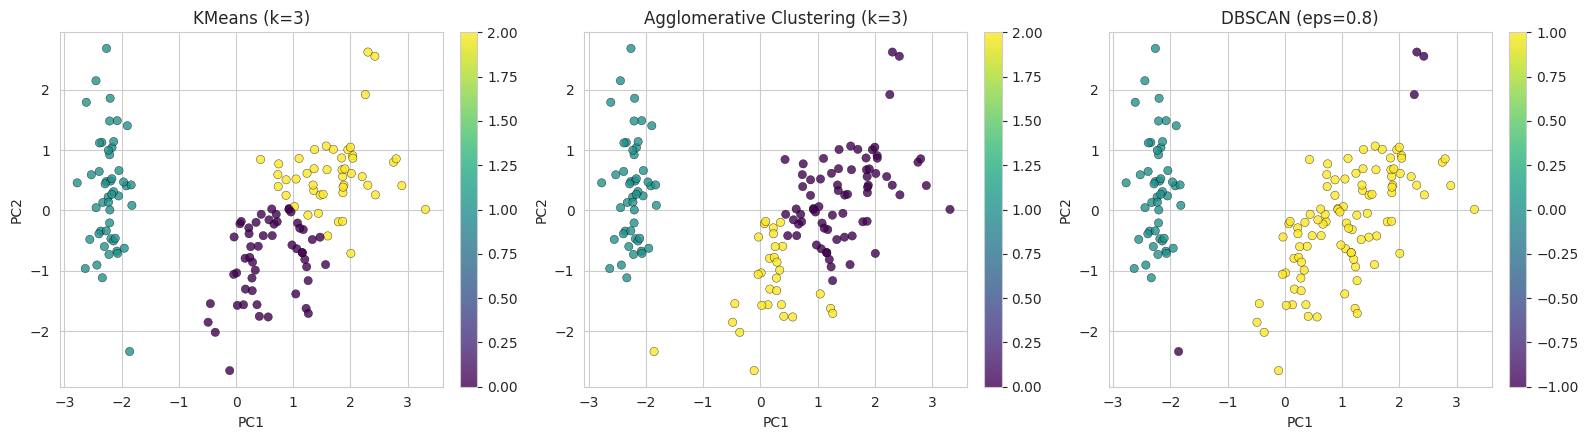

In [5]:
pca_2d = PCA(n_components=2, random_state=42)
X_pca = pca_2d.fit_transform(X_scaled)

kmeans_3 = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(X_scaled)
agg_3 = AgglomerativeClustering(n_clusters=3).fit_predict(X_scaled)
dbscan_res = DBSCAN(eps=0.8, min_samples=5).fit_predict(X_scaled)

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
plot_configs = [
    ("KMeans (k=3)", kmeans_3),
    ("Agglomerative Clustering (k=3)", agg_3),
    ("DBSCAN (eps=0.8)", dbscan_res)
]

for ax, (title, lbls) in zip(axes, plot_configs):
    sc = ax.scatter(X_pca[:, 0], X_pca[:, 1], c=lbls, cmap="viridis", alpha=0.8, edgecolor="k", linewidth=0.3)
    ax.set_title(title)
    ax.set_xlabel("PC1")
    ax.set_ylabel("PC2")
    plt.colorbar(sc, ax=ax, fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

### Nhận xét & Tổng kết Tuần 5:
* Phương pháp **Elbow** và **Silhouette Score** giúp xác định số cụm hợp lý khi làm việc với dữ liệu chưa có nhãn hoặc cần kiểm chứng cấu trúc tự nhiên của dữ liệu.
* Trực quan hóa trên mặt phẳng `PCA (2D)` cho thấy sự khác biệt về cách chia ranh giới và xử lý điểm nhiễu (`-1` trong `DBSCAN`) giữa các thuật toán.
* Bạn có thể thay thế bộ dữ liệu mẫu hoặc bổ sung thêm bước huấn luyện mô hình giám sát / tinh chỉnh siêu tham số tùy theo yêu cầu cụ thể của bài thực hành Tuần 5.